# Facial Emotion Recognition with CNN — FER2013
## Starter Notebook

</div>

---
## 📖 About the Dataset

**Source:** [FER2013 on Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

FER2013 (*Facial Expression Recognition 2013*) was introduced in a Kaggle competition in 2013 as part of the ICML workshop *"Challenges in Representation Learning"*. The faces were collected automatically from Google image search, so they are **real-world faces**: different ages, poses, lighting, glasses, hands covering the face, etc.

| Property | Value |
|---|---|
| Total images | ~35,900 |
| Image size | **48 × 48 pixels** |
| Color | **Grayscale** (1 channel) |
| Classes | **7 emotions** |
| Train / Test | ~28,700 / ~7,200 images |
| Format | `.jpg` files in one folder per class |

**The 7 classes:** `angry` 😠 · `disgust` 🤢 · `fear` 😨 · `happy` 😄 · `neutral` 😐 · `sad` 😢 · `surprise` 😲

**Folder structure:**
```
fer2013/
├── train/
│   ├── angry/     ├── disgust/   ├── fear/   ├── happy/
│   ├── neutral/   ├── sad/       └── surprise/
└── test/
    └── (same 7 folders)
```

### ⚠️ Things to know before you start
1. **The classes are imbalanced** — `happy` has ~7,000 training images while `disgust` has only ~400. A model can get "good" accuracy just by ignoring the rare classes, so look at **per-class** results, not only overall accuracy.
2. **The task is hard** — the images are small and blurry, and some emotions look alike (fear vs. surprise, sad vs. neutral). Human accuracy on this dataset is estimated at only **~65%**, so don't expect 95%!
3. **There is no validation set** — we will create one from the training set.
4. **Some labels are noisy** — a few images are mislabeled or are not faces at all.

<div dir="rtl">

---
## 📖 نبذة عن البيانات

**المصدر:** [FER2013 على Kaggle](https://www.kaggle.com/datasets/msambare/fer2013)

بيانات FER2013 (*التعرّف على تعابير الوجه 2013*) نُشرت في مسابقة على Kaggle عام 2013 ضمن ورشة ICML بعنوان *"تحديات تعلّم التمثيلات"*. جُمعت الوجوه تلقائياً من بحث صور Google، لذلك هي **وجوه من الواقع**: أعمار مختلفة، وضعيات مختلفة، إضاءة متفاوتة، نظارات، أيدٍ تغطي الوجه... إلخ.

| الخاصية | القيمة |
|---|---|
| عدد الصور الكلي | حوالي 35,900 |
| حجم الصورة | **48 × 48 بكسل** |
| الألوان | **رمادية (Grayscale)** — قناة واحدة |
| عدد الأصناف | **7 مشاعر** |
| تدريب / اختبار | حوالي 28,700 / 7,200 صورة |
| الصيغة | ملفات `.jpg` في مجلد لكل صنف |

**الأصناف السبعة:** `angry` غضب 😠 · `disgust` اشمئزاز 🤢 · `fear` خوف 😨 · `happy` سعادة 😄 · `neutral` محايد 😐 · `sad` حزن 😢 · `surprise` مفاجأة 😲

### ⚠️ أمور مهمة قبل البدء
1. **الأصناف غير متوازنة** — صنف `happy` فيه حوالي 7,000 صورة تدريب بينما `disgust` فيه حوالي 400 فقط. النموذج قد يحصل على دقة "جيدة" وهو يتجاهل الأصناف النادرة، لذلك انظر إلى النتائج **لكل صنف** وليس الدقة الكلية فقط.
2. **المهمة صعبة** — الصور صغيرة وغير واضحة، وبعض المشاعر متشابهة (الخوف والمفاجأة، الحزن والمحايد). دقة الإنسان على هذه البيانات تُقدّر بحوالي **65%** فقط، فلا تتوقع 95%!
3. **لا توجد بيانات تحقق (validation)** — سننشئها من بيانات التدريب.
4. **بعض التسميات فيها أخطاء** — بعض الصور مصنّفة خطأ أو ليست وجوهاً أصلاً.

</div>

---
## 1. Setup
> In Colab, enable the GPU: **Runtime → Change runtime type → T4 GPU**

<div dir="rtl">

## 1. الإعداد
> في Colab فعّل الـ GPU من: **Runtime → Change runtime type → T4 GPU**

</div>

In [ ]:
# Install kagglehub (used to download datasets from Kaggle)
# تثبيت مكتبة kagglehub لتحميل البيانات من Kaggle
!pip install -q kagglehub

In [ ]:
import os
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

from sklearn.model_selection import train_test_split

# ---- Reproducibility: same random results every run ----
# ---- تثبيت العشوائية: نفس النتائج في كل تشغيل ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Use the GPU if available, otherwise the CPU
# استخدم الـ GPU إن وُجد، وإلا الـ CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 2. Download the Data
We use `kagglehub` to download the dataset directly from Kaggle.
> If you get an authentication error: in Colab open 🔑 **Secrets** and add `KAGGLE_USERNAME` and `KAGGLE_KEY` (from Kaggle → Settings → API → Create New Token).

<div dir="rtl">

## 2. تحميل البيانات
نستخدم `kagglehub` لتحميل البيانات مباشرة من Kaggle.
> إذا ظهر خطأ في الصلاحيات: من Colab افتح 🔑 **Secrets** وأضف `KAGGLE_USERNAME` و `KAGGLE_KEY` (من Kaggle ← Settings ← API ← Create New Token).

</div>

In [ ]:
import kagglehub

# Download the dataset (it is cached, so running again is instant)
# تحميل البيانات (تُحفظ مؤقتاً، فإعادة التشغيل تكون فورية)
path = kagglehub.dataset_download("msambare/fer2013")
print("Downloaded to:", path)

# Locate the train/ and test/ folders
# تحديد مسار مجلدي التدريب والاختبار
TRAIN_DIR = os.path.join(path, "train")
TEST_DIR  = os.path.join(path, "test")
print("Train folder:", TRAIN_DIR, "| exists:", os.path.isdir(TRAIN_DIR))
print("Test folder: ", TEST_DIR,  "| exists:", os.path.isdir(TEST_DIR))
print("Class folders:", sorted(os.listdir(TRAIN_DIR)))

Using Colab cache for faster access to the 'fer2013' dataset.
Downloaded to: /kaggle/input/fer2013
Train folder: /kaggle/input/fer2013/train | exists: True
Test folder:  /kaggle/input/fer2013/test | exists: True
Class folders: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


## 3. Explore the Data

<div dir="rtl">

## 3. استكشاف البيانات

</div>

In [ ]:
# ImageFolder reads a "one folder per class" structure:
# the folder name becomes the class name, and each image gets that label.
# ImageFolder يقرأ البيانات المنظّمة بمجلد لكل صنف:
# اسم المجلد يصبح اسم الصنف، وكل صورة تأخذ تسمية مجلدها.
raw_train = datasets.ImageFolder(TRAIN_DIR)
raw_test  = datasets.ImageFolder(TEST_DIR)

CLASS_NAMES = raw_train.classes          # ['angry', 'disgust', 'fear', ...]
NUM_CLASSES = len(CLASS_NAMES)

print("Classes:", dict(enumerate(CLASS_NAMES)))
print("Train images:", len(raw_train))
print("Test images: ", len(raw_test))

# Check the size and mode of one image (L = grayscale)
# فحص حجم ونوع صورة واحدة (L تعني رمادية)
img, label = raw_train[0]
print("Image size:", img.size, "| mode:", img.mode, "| label:", CLASS_NAMES[label])

Classes: {0: 'angry', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'neutral', 5: 'sad', 6: 'surprise'}
Train images: 28709
Test images:  7178
Image size: (48, 48) | mode: RGB | label: angry


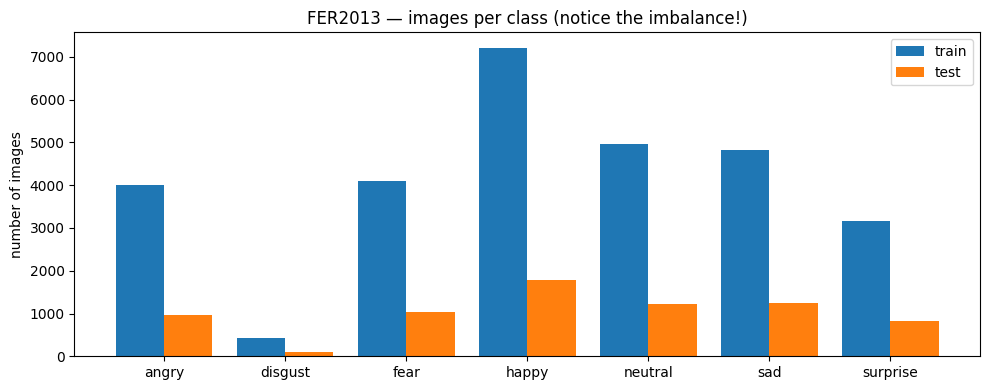

angry      train:  3995   test:   958
disgust    train:   436   test:   111
fear       train:  4097   test:  1024
happy      train:  7215   test:  1774
neutral    train:  4965   test:  1233
sad        train:  4830   test:  1247
surprise   train:  3171   test:   831


In [ ]:
# ---- Class distribution: how many images per emotion? ----
# ---- توزيع الأصناف: كم صورة لكل شعور؟ ----
train_counts = Counter(raw_train.targets)
test_counts  = Counter(raw_test.targets)

x = np.arange(NUM_CLASSES)
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, [train_counts[i] for i in range(NUM_CLASSES)], width=0.4, label="train")
plt.bar(x + 0.2, [test_counts[i]  for i in range(NUM_CLASSES)], width=0.4, label="test")
plt.xticks(x, CLASS_NAMES)
plt.ylabel("number of images")
plt.title("FER2013 — images per class (notice the imbalance!)")
plt.legend()
plt.tight_layout()
plt.show()

for i, name in enumerate(CLASS_NAMES):
    print(f"{name:<10} train: {train_counts[i]:>5}   test: {test_counts[i]:>5}")

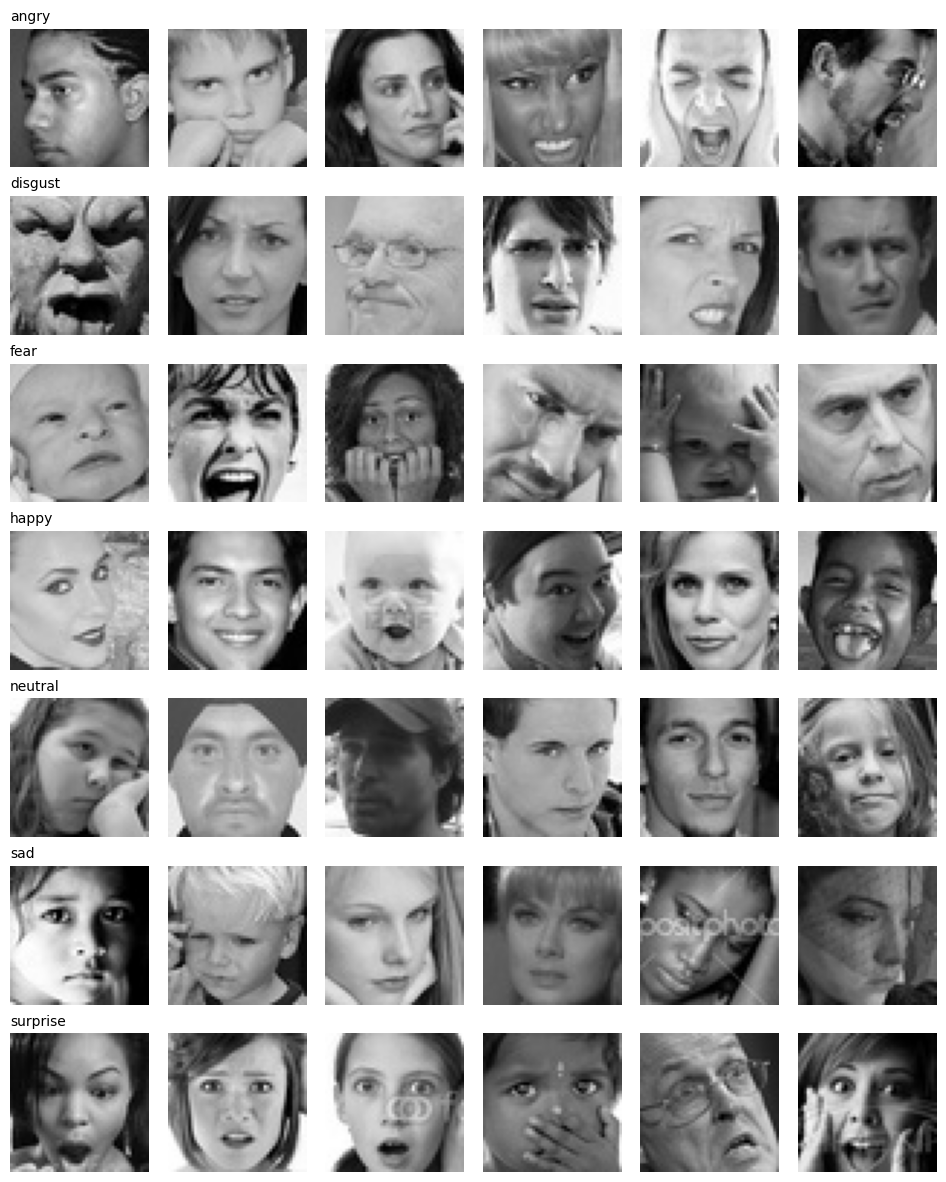

In [ ]:
# ---- Show random examples from each class ----
# ---- عرض أمثلة عشوائية من كل صنف ----
N_PER_CLASS = 6
train_targets = np.array(raw_train.targets)

fig, axes = plt.subplots(NUM_CLASSES, N_PER_CLASS, figsize=(N_PER_CLASS * 1.6, NUM_CLASSES * 1.7))
for c in range(NUM_CLASSES):
    # pick random image indices that belong to class c
    # اختيار صور عشوائية تنتمي للصنف c
    idxs = np.random.choice(np.where(train_targets == c)[0], N_PER_CLASS, replace=False)
    for j, idx in enumerate(idxs):
        img, _ = raw_train[idx]
        axes[c, j].imshow(img, cmap="gray")
        axes[c, j].axis("off")
    axes[c, 0].set_title(CLASS_NAMES[c], loc="left", fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
import os
import random
import copy
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from collections import Counter
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Existing dataset paths
TRAIN_DIR = "/kaggle/input/fer2013/train"
TEST_DIR = "/kaggle/input/fer2013/test"

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = 7

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_data_aug = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)
train_data_eval = datasets.ImageFolder(
    TRAIN_DIR, transform=eval_transform
)
test_data = datasets.ImageFolder(
    TEST_DIR, transform=eval_transform
)

CLASS_NAMES = train_data_aug.classes

indices = np.arange(len(train_data_aug))
targets = np.array(train_data_aug.targets)

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=SEED,
    stratify=targets
)

train_dataset = Subset(train_data_aug, train_idx)
val_dataset = Subset(train_data_eval, val_idx)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
)

# Class weights to address class imbalance
counts = np.bincount(
    targets[train_idx], minlength=NUM_CLASSES
)
class_weights = len(train_idx) / (
    NUM_CLASSES * counts
)
class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device
)

print("Using device:", device)
print("Classes:", CLASS_NAMES)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_data))
print("Data preparation completed!")

Using device: cuda
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
Training images: 22967
Validation images: 5742
Testing images: 7178
Data preparation completed!


In [ ]:
import torch
import torch.nn as nn

class CNNModel(nn.Module):

    def __init__(self, num_classes=7):
        super(CNNModel, self).__init__()

        self.features = nn.Sequential(

            # Convolution Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolution Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolution Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            # Convolution Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 3 * 3, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Initialize CNN
cnn_model = CNNModel(
    num_classes=7
).to(device)

print("CNN Model Created Successfully!")
print("Device:", device)
print("Number of Classes:", 7)

# Verify output shape
sample_input = torch.randn(1, 1, 48, 48).to(device)

with torch.no_grad():
    sample_output = cnn_model(sample_input)

print("Output Shape:", sample_output.shape)

CNN Model Created Successfully!
Device: cuda
Number of Classes: 7
Output Shape: torch.Size([1, 7])


In [ ]:
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
import numpy as np

# Dataset paths
TRAIN_DIR = "/kaggle/input/fer2013/train"
TEST_DIR = "/kaggle/input/fer2013/test"

BATCH_SIZE = 64

# CNN uses grayscale images (1 channel)
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_data = datasets.ImageFolder(
    TRAIN_DIR, transform=train_transform
)

val_data = datasets.ImageFolder(
    TRAIN_DIR, transform=test_transform
)

test_data = datasets.ImageFolder(
    TEST_DIR, transform=test_transform
)

indices = np.arange(len(train_data))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=train_data.targets
)

cnn_train_loader = DataLoader(
    Subset(train_data, train_idx),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

cnn_val_loader = DataLoader(
    Subset(val_data, val_idx),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

cnn_test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("CNN DataLoaders Ready!")
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_data))

CNN DataLoaders Ready!
Train: 22967
Validation: 5742
Test: 7178


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import copy
import matplotlib.pyplot as plt

# Training settings
EPOCHS = 10
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    cnn_model.parameters(),
    lr=LEARNING_RATE
)

# Store training results
cnn_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_val_acc = 0.0
best_model_weights = copy.deepcopy(cnn_model.state_dict())

for epoch in range(EPOCHS):

    # ===== Training =====
    cnn_model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in cnn_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = cnn_model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()

        total += labels.size(0)

    train_loss = running_loss / total
    train_acc = 100 * correct / total

    # ===== Validation =====
    cnn_model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in cnn_val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = cnn_model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * labels.size(0)
            val_correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = val_running_loss / val_total
    val_acc = 100 * val_correct / val_total

    cnn_history["train_loss"].append(train_loss)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["train_acc"].append(train_acc)
    cnn_history["val_acc"].append(val_acc)

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model_weights = copy.deepcopy(
            cnn_model.state_dict()
        )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%"
    )

# Restore best model
cnn_model.load_state_dict(best_model_weights)

# Save model
torch.save(
    cnn_model.state_dict(),
    "cnn_best_model.pth"
)

print("\nCNN Training Completed!")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print("Best model saved successfully!")

Epoch [1/10] | Train Loss: 1.7200 | Train Acc: 30.96% | Val Loss: 1.4745 | Val Acc: 42.65%
Epoch [2/10] | Train Loss: 1.4891 | Train Acc: 41.76% | Val Loss: 1.3603 | Val Acc: 47.02%
Epoch [3/10] | Train Loss: 1.4029 | Train Acc: 45.70% | Val Loss: 1.2818 | Val Acc: 50.70%
Epoch [4/10] | Train Loss: 1.3515 | Train Acc: 47.24% | Val Loss: 1.2501 | Val Acc: 52.70%
Epoch [5/10] | Train Loss: 1.3193 | Train Acc: 49.17% | Val Loss: 1.2190 | Val Acc: 53.76%
Epoch [6/10] | Train Loss: 1.2886 | Train Acc: 50.53% | Val Loss: 1.1937 | Val Acc: 54.06%
Epoch [7/10] | Train Loss: 1.2636 | Train Acc: 51.45% | Val Loss: 1.2015 | Val Acc: 54.11%
Epoch [8/10] | Train Loss: 1.2371 | Train Acc: 52.78% | Val Loss: 1.2110 | Val Acc: 53.74%
Epoch [9/10] | Train Loss: 1.2238 | Train Acc: 53.19% | Val Loss: 1.1523 | Val Acc: 57.04%
Epoch [10/10] | Train Loss: 1.1977 | Train Acc: 54.04% | Val Loss: 1.1280 | Val Acc: 57.35%

CNN Training Completed!
Best Validation Accuracy: 57.35%
Best model saved successfully!


CNN Test Accuracy: 56.45 %

CNN Classification Report:
              precision    recall  f1-score   support

       angry       0.54      0.37      0.44       958
     disgust       0.00      0.00      0.00       111
        fear       0.36      0.13      0.19      1024
       happy       0.79      0.84      0.82      1774
     neutral       0.56      0.50      0.52      1233
         sad       0.36      0.69      0.48      1247
    surprise       0.74      0.72      0.73       831

    accuracy                           0.56      7178
   macro avg       0.48      0.46      0.45      7178
weighted avg       0.56      0.56      0.55      7178



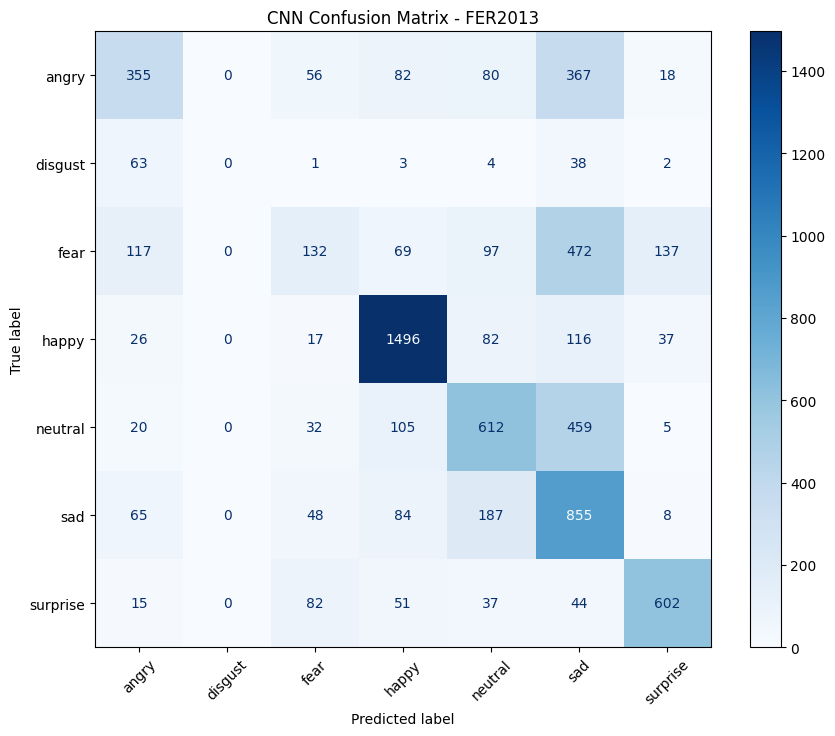

In [ ]:
import torch
import numpy as np

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

# Evaluate CNN on test dataset
cnn_model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in cnn_test_loader:

        images = images.to(device)

        outputs = cnn_model(images)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(
            predictions.cpu().numpy()
        )

# Calculate Test Accuracy
cnn_test_accuracy = accuracy_score(
    all_labels,
    all_predictions
) * 100

print("CNN Test Accuracy:", round(cnn_test_accuracy, 2), "%")

# Classification Report
print("\nCNN Classification Report:")

print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=cnn_test_loader.dataset.classes,
        zero_division=0
    )
)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cnn_test_loader.dataset.classes
)

fig, ax = plt.subplots(figsize=(10, 8))
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45)
plt.title("CNN Confusion Matrix - FER2013")
plt.show()

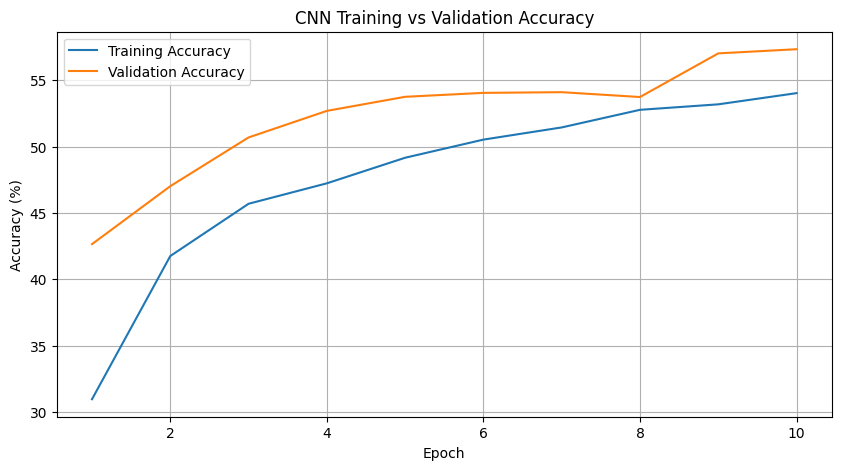

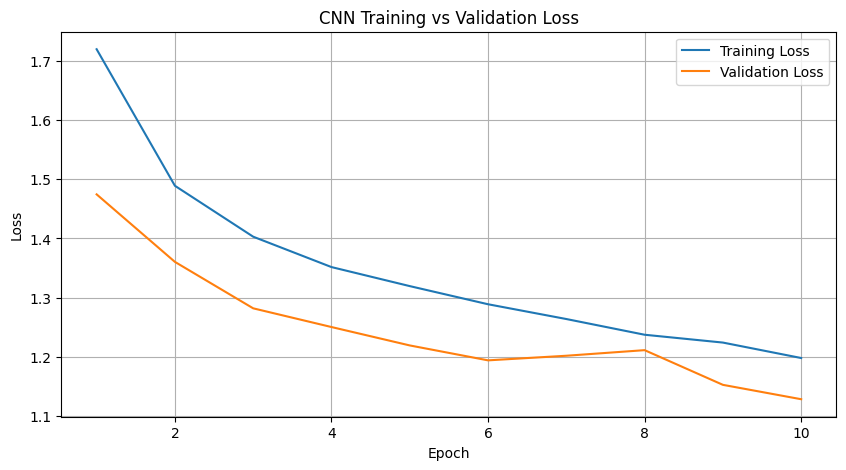

In [ ]:
epochs = range(1, len(cnn_history["train_acc"]) + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    cnn_history["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs,
    cnn_history["val_acc"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    cnn_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs,
    cnn_history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import numpy as np

RESNET_BATCH_SIZE = 32

resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

resnet_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

resnet_train_data = datasets.ImageFolder(
    TRAIN_DIR,
    transform=resnet_train_transform
)

resnet_val_data = datasets.ImageFolder(
    TRAIN_DIR,
    transform=resnet_test_transform
)

resnet_test_data = datasets.ImageFolder(
    TEST_DIR,
    transform=resnet_test_transform
)

# Same train/validation split as CNN
resnet_train_loader = DataLoader(
    Subset(resnet_train_data, train_idx),
    batch_size=RESNET_BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

resnet_val_loader = DataLoader(
    Subset(resnet_val_data, val_idx),
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

resnet_test_loader = DataLoader(
    resnet_test_data,
    batch_size=RESNET_BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("ResNet18 Data Preparation Completed!")
print("Training:", len(train_idx))
print("Validation:", len(val_idx))
print("Testing:", len(resnet_test_data))
print("Classes:", len(resnet_train_data.classes))

ResNet18 Data Preparation Completed!
Training: 22967
Validation: 5742
Testing: 7178
Classes: 7


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Number of emotion classes
RESNET_NUM_CLASSES = 7

# Load pretrained ResNet18
resnet_model = models.resnet18(
    weights=models.ResNet18_Weights.DEFAULT
)

# Freeze pretrained layers
for param in resnet_model.parameters():
    param.requires_grad = False

# Replace final classification layer
resnet_model.fc = nn.Linear(
    resnet_model.fc.in_features,
    RESNET_NUM_CLASSES
)

# Move model to GPU
resnet_model = resnet_model.to(device)

# Verify the model
print("ResNet18 Model Created Successfully!")
print("Device:", device)
print("Number of Classes:", RESNET_NUM_CLASSES)

sample_input = torch.randn(1, 3, 224, 224).to(device)

resnet_model.eval()

with torch.no_grad():
    sample_output = resnet_model(sample_input)

print("Output Shape:", sample_output.shape)

# Count trainable parameters
trainable_params = sum(
    p.numel()
    for p in resnet_model.parameters()
    if p.requires_grad
)

print("Trainable Parameters:", trainable_params)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 46.4MB/s]


ResNet18 Model Created Successfully!
Device: cuda
Number of Classes: 7
Output Shape: torch.Size([1, 7])
Trainable Parameters: 3591


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import copy

# ==========================================
# 1. إعدادات تدريب نموذج ResNet18
# ==========================================

# تحديد عدد دورات التدريب
RESNET_EPOCHS = 10

# تحديد معدل التعلم
RESNET_LEARNING_RATE = 0.001

# تحديد دالة حساب الخطأ
resnet_criterion = nn.CrossEntropyLoss()

# تحديد المحسن لتحديث أوزان الطبقات القابلة للتدريب فقط
resnet_optimizer = optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet_model.parameters()
    ),
    lr=RESNET_LEARNING_RATE
)

# ==========================================
# 2. إنشاء متغيرات لحفظ نتائج التدريب
# ==========================================

resnet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

# حفظ أفضل دقة وأفضل أوزان للنموذج
resnet_best_val_acc = 0.0
resnet_best_weights = copy.deepcopy(
    resnet_model.state_dict()
)

# ==========================================
# 3. بدء تدريب نموذج ResNet18
# ==========================================

for epoch in range(RESNET_EPOCHS):

    # تفعيل وضع التدريب
    resnet_model.train()

    # إبقاء الطبقات المجمدة في وضع التقييم
    # لمنع تحديث إحصائيات Batch Normalization
    for module in resnet_model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    # المرور على جميع دفعات صور التدريب
    for images, labels in resnet_train_loader:

        # نقل الصور والتصنيفات إلى GPU
        images = images.to(device)
        labels = labels.to(device)

        # تصفير التدرجات السابقة
        resnet_optimizer.zero_grad()

        # تمرير الصور داخل النموذج
        outputs = resnet_model(images)

        # حساب الخطأ
        loss = resnet_criterion(outputs, labels)

        # حساب التدرجات وتحديث الأوزان
        loss.backward()
        resnet_optimizer.step()

        # تجميع خسارة التدريب
        train_loss_sum += loss.item() * labels.size(0)

        # حساب عدد التوقعات الصحيحة
        predictions = outputs.argmax(dim=1)

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    # حساب متوسط الخطأ ودقة التدريب
    train_loss = train_loss_sum / train_total
    train_acc = 100 * train_correct / train_total

    # ======================================
    # 4. التحقق من أداء النموذج Validation
    # ======================================

    # تفعيل وضع التقييم
    resnet_model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    # إيقاف حساب التدرجات لتقليل استهلاك الذاكرة
    with torch.no_grad():

        for images, labels in resnet_val_loader:

            # نقل البيانات إلى GPU
            images = images.to(device)
            labels = labels.to(device)

            # الحصول على توقعات النموذج
            outputs = resnet_model(images)

            # حساب خطأ التحقق
            loss = resnet_criterion(outputs, labels)

            val_loss_sum += loss.item() * labels.size(0)

            # حساب التوقعات الصحيحة
            predictions = outputs.argmax(dim=1)

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    # حساب دقة وخطأ التحقق
    val_loss = val_loss_sum / val_total
    val_acc = 100 * val_correct / val_total

    # ======================================
    # 5. حفظ نتائج كل Epoch
    # ======================================

    resnet_history["train_loss"].append(train_loss)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["train_acc"].append(train_acc)
    resnet_history["val_acc"].append(val_acc)

    # حفظ أفضل نموذج بناءً على دقة التحقق
    if val_acc > resnet_best_val_acc:

        resnet_best_val_acc = val_acc

        resnet_best_weights = copy.deepcopy(
            resnet_model.state_dict()
        )

        # حفظ أفضل نموذج على القرص مباشرة
        torch.save(
            resnet_best_weights,
            "resnet18_best_model.pth"
        )

    # عرض نتائج الدورة الحالية
    print(
        f"Epoch [{epoch+1}/{RESNET_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}%",
        flush=True
    )

# ==========================================
# 6. استرجاع أفضل نسخة من النموذج
# ==========================================

resnet_model.load_state_dict(
    resnet_best_weights
)

print("\nResNet18 Training Completed!")
print(
    f"Best Validation Accuracy: "
    f"{resnet_best_val_acc:.2f}%"
)
print("Best model saved successfully!")

Epoch [1/10] | Train Loss: 1.5769 | Train Acc: 38.95% | Val Loss: 1.4974 | Val Acc: 42.15%
Epoch [2/10] | Train Loss: 1.4762 | Train Acc: 43.84% | Val Loss: 1.4610 | Val Acc: 44.74%
Epoch [3/10] | Train Loss: 1.4433 | Train Acc: 45.33% | Val Loss: 1.4712 | Val Acc: 44.34%
Epoch [4/10] | Train Loss: 1.4229 | Train Acc: 46.35% | Val Loss: 1.4379 | Val Acc: 46.43%
Epoch [5/10] | Train Loss: 1.4065 | Train Acc: 46.64% | Val Loss: 1.4755 | Val Acc: 45.23%
Epoch [6/10] | Train Loss: 1.4086 | Train Acc: 46.81% | Val Loss: 1.4309 | Val Acc: 46.46%
Epoch [7/10] | Train Loss: 1.4030 | Train Acc: 46.92% | Val Loss: 1.4745 | Val Acc: 44.50%
Epoch [8/10] | Train Loss: 1.3963 | Train Acc: 47.23% | Val Loss: 1.4359 | Val Acc: 46.48%
Epoch [9/10] | Train Loss: 1.3854 | Train Acc: 47.52% | Val Loss: 1.4131 | Val Acc: 47.32%
Epoch [10/10] | Train Loss: 1.3863 | Train Acc: 47.74% | Val Loss: 1.4165 | Val Acc: 47.16%

ResNet18 Training Completed!
Best Validation Accuracy: 47.32%
Best model saved successfu

ResNet18 Test Accuracy: 46.31%
ResNet18 Macro F1-score: 0.3811

ResNet18 Classification Report:
              precision    recall  f1-score   support

       angry       0.33      0.38      0.35       958
     disgust       0.00      0.00      0.00       111
        fear       0.33      0.22      0.27      1024
       happy       0.60      0.66      0.63      1774
     neutral       0.41      0.52      0.46      1233
         sad       0.40      0.34      0.37      1247
    surprise       0.59      0.59      0.59       831

    accuracy                           0.46      7178
   macro avg       0.38      0.39      0.38      7178
weighted avg       0.45      0.46      0.45      7178



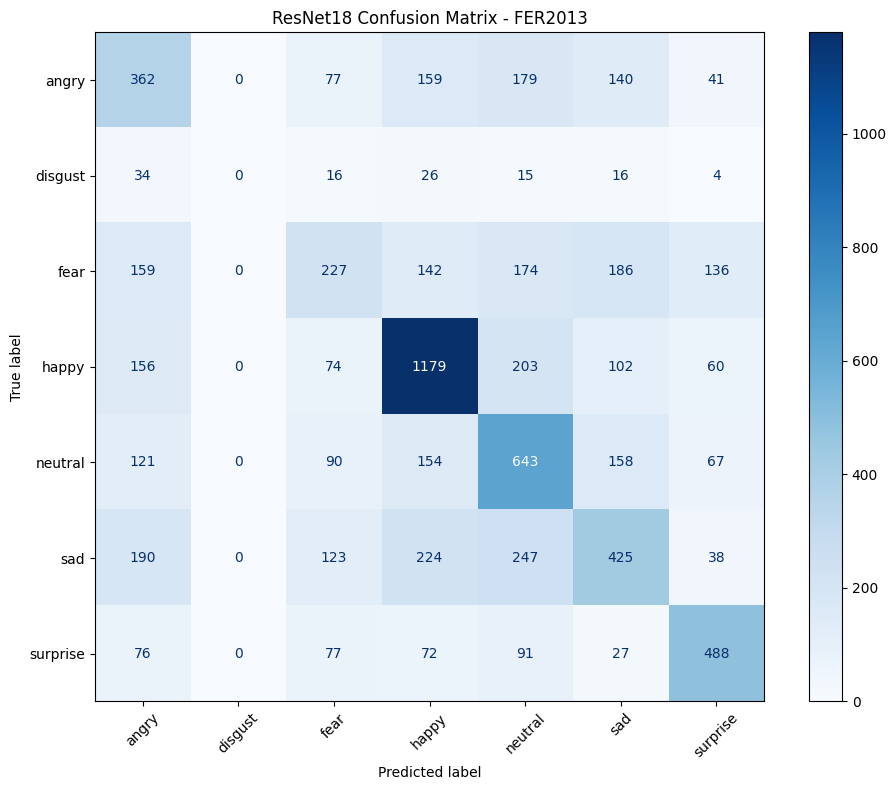

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# ==========================================
# 1. تجهيز النموذج للاختبار
# ==========================================

# تفعيل وضع التقييم لإيقاف سلوك التدريب
resnet_model.eval()

# إنشاء قوائم لتجميع النتائج الحقيقية والمتوقعة
resnet_true_labels = []
resnet_predictions = []

# ==========================================
# 2. اختبار النموذج على جميع صور الاختبار
# ==========================================

# إيقاف حساب التدرجات لتوفير الذاكرة
with torch.no_grad():

    for images, labels in resnet_test_loader:

        # نقل الصور إلى GPU
        images = images.to(device)

        # الحصول على توقعات النموذج
        outputs = resnet_model(images)

        # اختيار الفئة الأعلى في درجات التوقع
        predictions = outputs.argmax(dim=1)

        # حفظ التصنيفات الحقيقية والمتوقعة
        resnet_true_labels.extend(labels.numpy())
        resnet_predictions.extend(
            predictions.cpu().numpy()
        )

# ==========================================
# 3. حساب Accuracy وMacro F1-score
# ==========================================

resnet_test_accuracy = accuracy_score(
    resnet_true_labels,
    resnet_predictions
) * 100

resnet_macro_f1 = f1_score(
    resnet_true_labels,
    resnet_predictions,
    average="macro",
    zero_division=0
)

print("ResNet18 Test Accuracy:",
      f"{resnet_test_accuracy:.2f}%")

print("ResNet18 Macro F1-score:",
      f"{resnet_macro_f1:.4f}")

# ==========================================
# 4. طباعة تقرير تصنيف المشاعر
# ==========================================

resnet_classes = resnet_test_loader.dataset.classes

print("\nResNet18 Classification Report:")

print(
    classification_report(
        resnet_true_labels,
        resnet_predictions,
        target_names=resnet_classes,
        zero_division=0
    )
)

# ==========================================
# 5. رسم مصفوفة الالتباس
# ==========================================

cm = confusion_matrix(
    resnet_true_labels,
    resnet_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=resnet_classes
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("ResNet18 Confusion Matrix - FER2013")
plt.tight_layout()
plt.show()

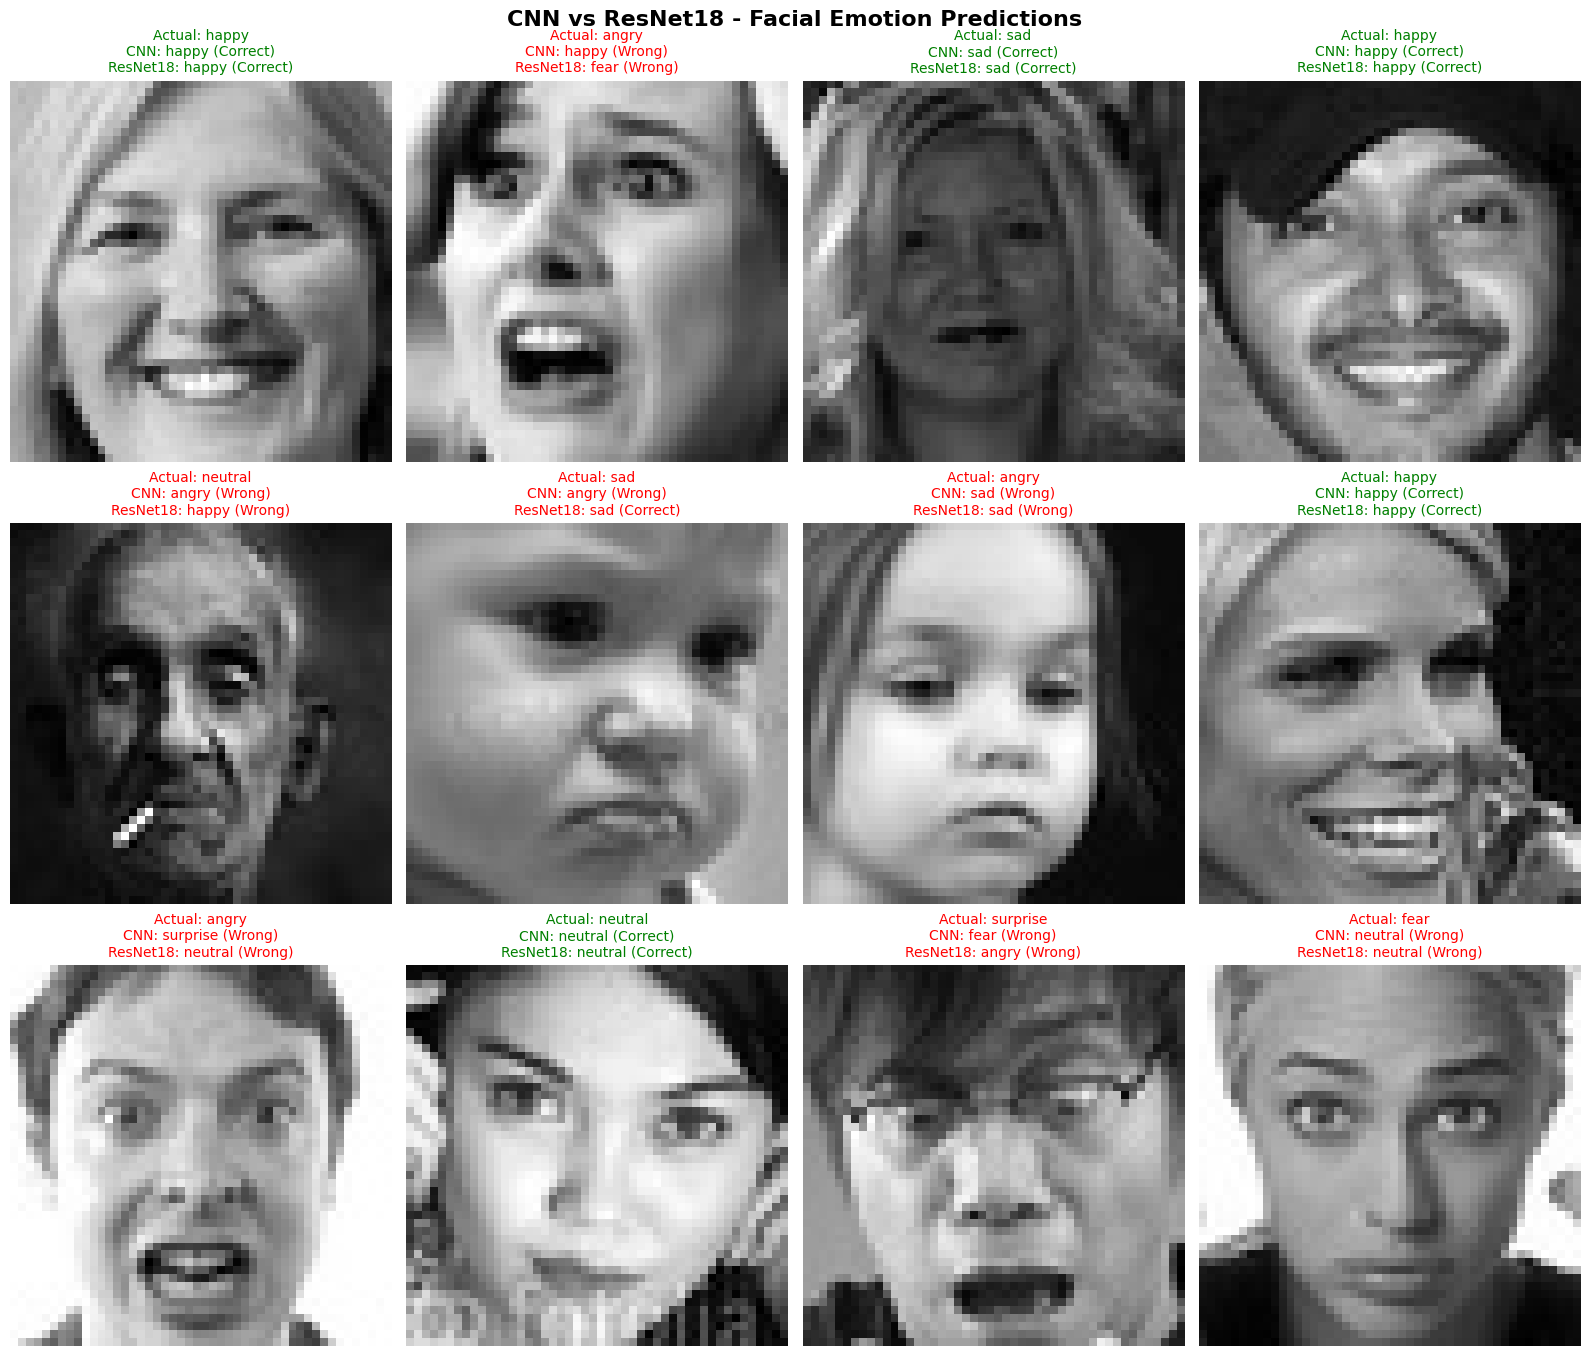

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. تجهيز النموذجين للاختبار
# ==========================================

# تفعيل وضع التقييم
cnn_model.eval()
resnet_model.eval()

# استخراج أسماء المشاعر السبع
class_names = cnn_test_loader.dataset.classes

# ==========================================
# 2. اختيار صور من مجموعة الاختبار
# ==========================================

# اختيار 12 صورة عشوائية مع تثبيت الاختيار
rng = np.random.default_rng(42)

sample_indices = rng.choice(
    len(cnn_test_loader.dataset),
    size=12,
    replace=False
)

# ==========================================
# 3. عرض الصور وتوقعات النموذجين
# ==========================================

fig, axes = plt.subplots(3, 4, figsize=(16, 14))

with torch.no_grad():

    for ax, idx in zip(axes.flat, sample_indices):

        # الحصول على نفس الصورة للنموذجين
        cnn_image, true_label = (
            cnn_test_loader.dataset[int(idx)]
        )

        resnet_image, _ = (
            resnet_test_loader.dataset[int(idx)]
        )

        # تجهيز صورة CNN
        cnn_input = cnn_image.unsqueeze(0).to(device)

        # تجهيز صورة ResNet18
        resnet_input = resnet_image.unsqueeze(0).to(device)

        # الحصول على توقع CNN
        cnn_output = cnn_model(cnn_input)
        cnn_pred = cnn_output.argmax(dim=1).item()

        # الحصول على توقع ResNet18
        resnet_output = resnet_model(resnet_input)
        resnet_pred = resnet_output.argmax(dim=1).item()

        # إعادة الصورة الرمادية إلى نطاق العرض
        display_image = cnn_image.squeeze().cpu().numpy()
        display_image = display_image * 0.5 + 0.5
        display_image = np.clip(display_image, 0, 1)

        # عرض صورة الوجه
        ax.imshow(display_image, cmap="gray")
        ax.axis("off")

        # تحديد صحة توقع كل نموذج
        cnn_correct = cnn_pred == true_label
        resnet_correct = resnet_pred == true_label

        cnn_status = "Correct" if cnn_correct else "Wrong"
        resnet_status = "Correct" if resnet_correct else "Wrong"

        # عرض التصنيف الحقيقي وتوقعات النموذجين
        ax.set_title(
            f"Actual: {class_names[true_label]}\n"
            f"CNN: {class_names[cnn_pred]} ({cnn_status})\n"
            f"ResNet18: {class_names[resnet_pred]} ({resnet_status})",
            fontsize=10,
            color=(
                "green" if cnn_correct and resnet_correct
                else "red"
            )
        )

plt.suptitle(
    "CNN vs ResNet18 - Facial Emotion Predictions",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
NUM_CLASSES =7
print ("NUCLASSES :",NUM_CLASSES)


NUCLASSES : 7


In [ ]:
import torch.nn as nn
import timm

print("--- Loading EfficientNet-B1 for Fine-Tuning ---")

# 1. تحميل النموذج وتعديل الطبقة الأخيرة لتناسب عدد الفئات لديك
model_eff = timm.create_model('efficientnet_b1', pretrained=True, num_classes=NUM_CLASSES)
model_eff = model_eff.to(device)

# ==========================================
# 2. فك تجميد الطبقات المتعددة (الجديد هنا)
# ==========================================
# أولاً: تجميد كافة أوزان النموذج الأساسية
for param in model_eff.parameters():
    param.requires_grad = False

# ثانياً: فك التجميد عن الطبقات الأخيرة فقط (مثل الـ Classifier والكتل المتقدمة الأخيرة)
for name, param in model_eff.named_parameters():
    if "classifier" in name or "blocks.6" in name or "blocks.5" in name:
        param.requires_grad = True
        print(f"Unfrozen layer: {name}")

# ==========================================
# 3. إعداد دالة الخسارة والمحسن (Optimizer)
# ==========================================
criterion = nn.CrossEntropyLoss()

# مهم جداً: نجعل الـ Optimizer يتدرب فقط على الطبقات التي أزلنا عنها التجميد (requires_grad = True)
optimizer_eff = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model_eff.parameters()),
    lr=1e-5,
    weight_decay=1e-2
)

print("Model is ready for multi-layer fine-tuning!")

--- Loading EfficientNet-B1 for Fine-Tuning ---
Unfrozen layer: blocks.5.0.conv_pw.weight
Unfrozen layer: blocks.5.0.bn1.weight
Unfrozen layer: blocks.5.0.bn1.bias
Unfrozen layer: blocks.5.0.conv_dw.weight
Unfrozen layer: blocks.5.0.bn2.weight
Unfrozen layer: blocks.5.0.bn2.bias
Unfrozen layer: blocks.5.0.se.conv_reduce.weight
Unfrozen layer: blocks.5.0.se.conv_reduce.bias
Unfrozen layer: blocks.5.0.se.conv_expand.weight
Unfrozen layer: blocks.5.0.se.conv_expand.bias
Unfrozen layer: blocks.5.0.conv_pwl.weight
Unfrozen layer: blocks.5.0.bn3.weight
Unfrozen layer: blocks.5.0.bn3.bias
Unfrozen layer: blocks.5.1.conv_pw.weight
Unfrozen layer: blocks.5.1.bn1.weight
Unfrozen layer: blocks.5.1.bn1.bias
Unfrozen layer: blocks.5.1.conv_dw.weight
Unfrozen layer: blocks.5.1.bn2.weight
Unfrozen layer: blocks.5.1.bn2.bias
Unfrozen layer: blocks.5.1.se.conv_reduce.weight
Unfrozen layer: blocks.5.1.se.conv_reduce.bias
Unfrozen layer: blocks.5.1.se.conv_expand.weight
Unfrozen layer: blocks.5.1.se.conv

--- Starting Fine-Tuning Training Loop ---
Epoch [1/10] | Train Loss: 2.3829 - Train Acc: 30.47% | Val Loss: 1.8638 - Val Acc: 36.68%
Epoch [2/10] | Train Loss: 1.5863 - Train Acc: 42.93% | Val Loss: 1.5607 - Val Acc: 43.62%
Epoch [3/10] | Train Loss: 1.3640 - Train Acc: 49.31% | Val Loss: 1.4027 - Val Acc: 48.86%
Epoch [4/10] | Train Loss: 1.2388 - Train Acc: 53.82% | Val Loss: 1.3080 - Val Acc: 51.09%
Epoch [5/10] | Train Loss: 1.1539 - Train Acc: 56.65% | Val Loss: 1.2230 - Val Acc: 53.96%
Epoch [6/10] | Train Loss: 1.0888 - Train Acc: 59.56% | Val Loss: 1.1798 - Val Acc: 55.89%
Epoch [7/10] | Train Loss: 1.0330 - Train Acc: 61.32% | Val Loss: 1.1580 - Val Acc: 56.59%
Epoch [8/10] | Train Loss: 0.9873 - Train Acc: 63.43% | Val Loss: 1.1339 - Val Acc: 57.65%
Epoch [9/10] | Train Loss: 0.9339 - Train Acc: 65.13% | Val Loss: 1.1260 - Val Acc: 58.83%
Epoch [10/10] | Train Loss: 0.8921 - Train Acc: 66.95% | Val Loss: 1.1176 - Val Acc: 58.82%
Fine-Tuning Finished Successfully!


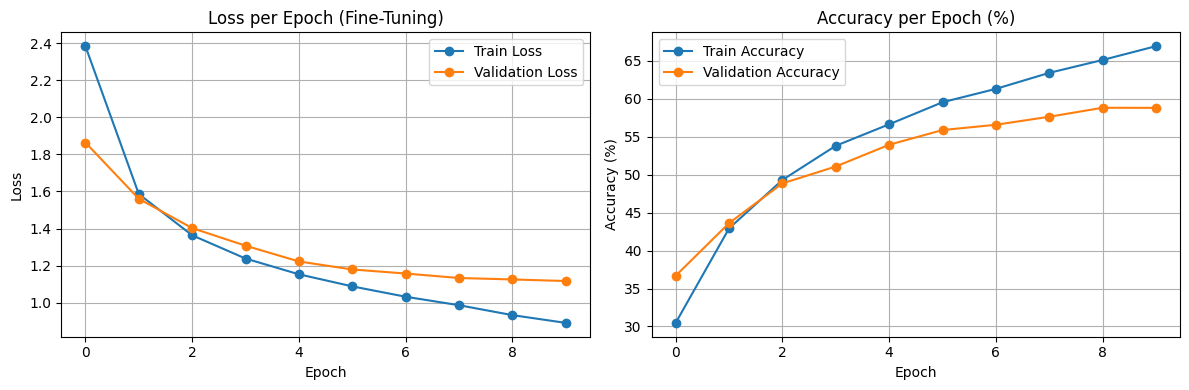

In [ ]:
import matplotlib.pyplot as plt

# تعريف القوائم لتخزين النتائج ورسمها لاحقاً
train_losses, test_losses = [], []
train_accs, test_accs = [], []

EPOCHS = 10

print("--- Starting Fine-Tuning Training Loop ---")

for epoch in range(EPOCHS):
    # --- 1. مرحلة التدريب (Training) ---
    model_eff.train()
    running_loss, correct_train, total_train = 0.0, 0, 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer_eff.zero_grad()
        outputs = model_eff(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_eff.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    train_loss = running_loss / total_train
    train_acc = correct_train / total_train

    # --- 2. مرحلة التحقق / التقييم (Validation / Test) ---
    model_eff.eval()
    test_loss, correct_test, total_test = 0.0, 0, 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_eff(images)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            total_test += labels.size(0)
            correct_test += predicted.eq(labels).sum().item()

    test_loss = test_loss / total_test
    test_acc = correct_test / total_test

    # حفظ النتائج في القوائم
    train_losses.append(train_loss)
    test_losses.append(test_loss)
    train_accs.append(train_acc * 100)
    test_accs.append(test_acc * 100)

    print(f"Epoch [{epoch+1}/{EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} - Train Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {test_loss:.4f} - Val Acc: {test_acc*100:.2f}%")

print("Fine-Tuning Finished Successfully!")

# --- 3. رسم المنحنيات البيانية للنتائج ---
plt.figure(figsize=(12, 4))

# رسم الـ Loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss', marker='o')
plt.plot(test_losses, label='Validation Loss', marker='o')
plt.title('Loss per Epoch (Fine-Tuning)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# رسم الـ Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accs, label='Train Accuracy', marker='o')
plt.plot(test_accs, label='Validation Accuracy', marker='o')
plt.title('Accuracy per Epoch (%)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

EfficientNet Test Accuracy: 58.82%
EfficientNet Macro F1-score: 0.5395

EfficientNet Classification Report:
              precision    recall  f1-score   support

       angry       0.48      0.54      0.51       958
     disgust       0.48      0.26      0.34       111
        fear       0.48      0.33      0.39      1024
       happy       0.84      0.80      0.82      1774
     neutral       0.51      0.58      0.54      1233
         sad       0.43      0.52      0.47      1247
    surprise       0.74      0.68      0.70       831

    accuracy                           0.59      7178
   macro avg       0.57      0.53      0.54      7178
weighted avg       0.60      0.59      0.59      7178



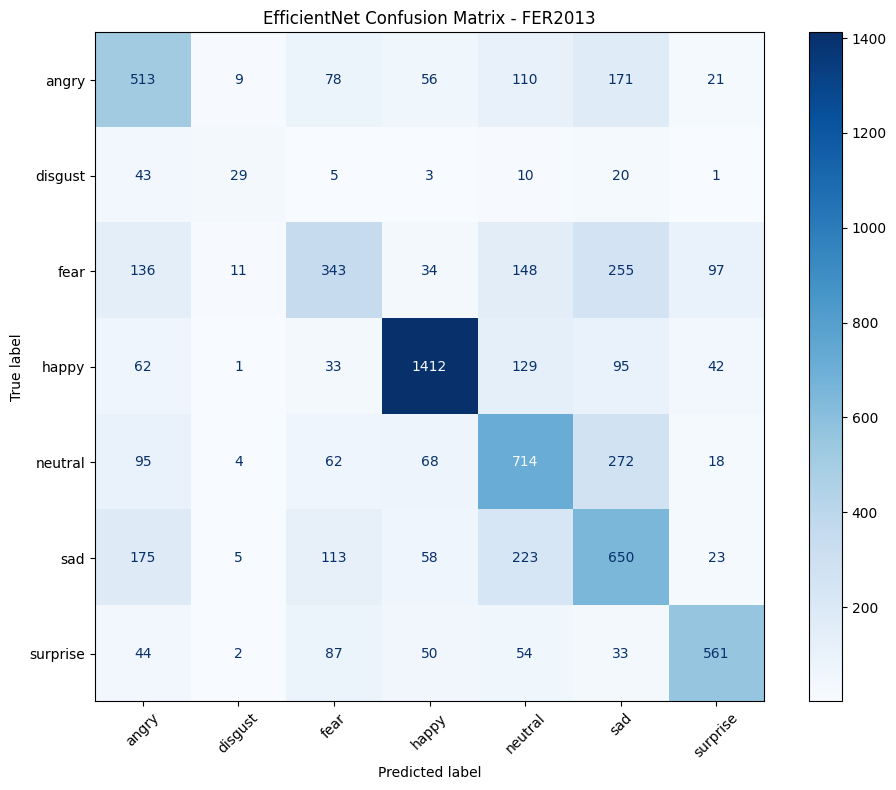

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

# ==========================================
# 1. تجهيز نموذج EfficientNet للاختبار
# ==========================================

# تفعيل وضع التقييم لإيقاف سلوك التدريب (مثل Dropout و BatchNorm)
model_eff.eval()

# إنشاء قوائم لتجميع النتائج الحقيقية والمتوقعة
eff_true_labels = []
eff_predictions = []

# ==========================================
# 2. اختبار النموذج على جميع صور الاختبار
# ==========================================

# إيقاف حساب التدرجات لتوفير الذاكرة والوقت
with torch.no_grad():
    for images, labels in test_loader:

        # نقل الصور إلى GPU
        images = images.to(device)

        # الحصول على توقعات النموذج
        outputs = model_eff(images)

        # اختيار الفئة الأعلى في درجات التوقع
        predictions = outputs.argmax(dim=1)

        # حفظ التصنيفات الحقيقية والمتوقعة (مع نقل التوقعات للـ CPU وتثبيتها)
        eff_true_labels.extend(labels.numpy())
        eff_predictions.extend(predictions.cpu().numpy())

# ==========================================
# 3. حساب Accuracy وMacro F1-score
# ==========================================

eff_test_accuracy = accuracy_score(
    eff_true_labels,
    eff_predictions
) * 100

eff_macro_f1 = f1_score(
    eff_true_labels,
    eff_predictions,
    average="macro",
    zero_division=0
)

print("EfficientNet Test Accuracy:",
      f"{eff_test_accuracy:.2f}%")

print("EfficientNet Macro F1-score:",
      f"{eff_macro_f1:.4f}")

# ==========================================
# 4. طباعة تقرير تصنيف المشاعر
# ==========================================

# استخراج أسماء الفئات (المشاعر) من الـ dataset
eff_classes = test_loader.dataset.classes

print("\nEfficientNet Classification Report:")
print(
    classification_report(
        eff_true_labels,
        eff_predictions,
        target_names=eff_classes,
        zero_division=0
    )
)

# ==========================================
# 5. رسم مصفوفة الالتباس (Confusion Matrix)
# ==========================================

cm = confusion_matrix(
    eff_true_labels,
    eff_predictions
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=eff_classes
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("EfficientNet Confusion Matrix - FER2013")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from IPython.display import display

# ==========================================
# 1. إدخال نتائج النماذج الثلاثة
# القيم مأخوذة من نتائج الاختبار الفعلية
# ==========================================

comparison_results = pd.DataFrame({
    "Model": [
        "CNN",
        "ResNet18",
        "EfficientNet-B1"
    ],
    "Accuracy (%)": [56.45, 46.31, 58.82],
    "Precision (%)": [48.00, 38.00, 57.00],
    "Recall (%)": [46.00, 39.00, 53.00],
    "F1-score (%)": [45.00, 38.11, 53.95]
})

# ==========================================
# 2. تمييز أعلى نتيجة في كل مقياس
# ==========================================

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1-score (%)"
]

styled_results = (
    comparison_results.style
    .highlight_max(subset=metrics, color="#c6efce")
    .format({metric: "{:.2f}%" for metric in metrics})
    .set_caption("FER2013 - Model Performance Comparison")
)

# ==========================================
# 3. عرض الجدول النهائي
# ==========================================

display(styled_results)

# ==========================================
# 4. تحديد أفضل نموذج حسب دقة الاختبار
# ==========================================

best_model = comparison_results.loc[
    comparison_results["Accuracy (%)"].idxmax(),
    "Model"
]

print("Best Model Based on Test Accuracy:", best_model)

,Model,Accuracy (%),Precision (%),Recall (%),F1-score (%)
0,CNN,56.45%,48.00%,46.00%,45.00%
1,ResNet18,46.31%,38.00%,39.00%,38.11%
2,EfficientNet-B1,58.82%,57.00%,53.00%,53.95%


Best Model Based on Test Accuracy: EfficientNet-B1


In [ ]:
from torch.utils.data import DataLoader

# ==========================================
# البحث عن جميع متغيرات DataLoader
# الموجودة في المشروع
# ==========================================

for name, value in list(globals().items()):

    # التأكد أن المتغير من نوع DataLoader
    if isinstance(value, DataLoader):

        # عرض اسم المتغير وعدد الصور
        print(
            f"Name: {name} | "
            f"Images: {len(value.dataset)}"
        )

Name: train_loader | Images: 22967
Name: val_loader | Images: 5742
Name: test_loader | Images: 7178
Name: cnn_train_loader | Images: 22967
Name: cnn_val_loader | Images: 5742
Name: cnn_test_loader | Images: 7178
Name: resnet_train_loader | Images: 22967
Name: resnet_val_loader | Images: 5742
Name: resnet_test_loader | Images: 7178


In [ ]:
# ==========================================
# 1. فحص بيانات الاختبار الحالية
# ==========================================

# عرض عدد صور الاختبار
print("Test images:", len(test_loader.dataset))

# عرض حجم الصورة وعدد القنوات
image, label = test_loader.dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

# عرض نوع معالجة الصور المستخدمة
print("Transform:")
print(test_loader.dataset.transform)

Test images: 7178
Image shape: torch.Size([3, 224, 224])
Label: 0
Transform:
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from torchvision.transforms import InterpolationMode

# ==========================================
# 1. تحديد إعدادات صور EfficientNet-B1
# ==========================================

EFF_IMAGE_SIZE = 240
EFF_BATCH_SIZE = 32

# ==========================================
# 2. تجهيز معالجة صور الاختبار
# ==========================================

eff_test_transform = transforms.Compose([

    # تحويل الصور إلى ثلاث قنوات
    transforms.Grayscale(num_output_channels=3),

    # تغيير حجم الصور إلى 240×240
    transforms.Resize(
        (EFF_IMAGE_SIZE, EFF_IMAGE_SIZE),
        interpolation=InterpolationMode.BILINEAR
    ),

    # تحويل الصور إلى Tensor
    transforms.ToTensor(),

    # تطبيق تطبيع ImageNet
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ==========================================
# 3. تحميل صور الاختبار
# ==========================================

eff_test_data = datasets.ImageFolder(
    TEST_DIR,
    transform=eff_test_transform
)

# ==========================================
# 4. إنشاء DataLoader للاختبار
# ==========================================

eff_test_loader = DataLoader(
    eff_test_data,
    batch_size=EFF_BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

# ==========================================
# 5. التأكد من جاهزية البيانات
# ==========================================

image, label = eff_test_data[0]

print("EfficientNet-B1 Test Loader Ready!")
print("Test images:", len(eff_test_data))
print("Image shape:", image.shape)
print("Classes:", eff_test_data.classes)

EfficientNet-B1 Test Loader Ready!
Test images: 7178
Image shape: torch.Size([3, 240, 240])
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [ ]:
# ==========================================
# التأكد من أن النماذج تستخدم صور الاختبار نفسها
# وبالترتيب نفسه
# ==========================================

cnn_paths = [
    path for path, _ in cnn_test_loader.dataset.samples
]

resnet_paths = [
    path for path, _ in resnet_test_loader.dataset.samples
]

eff_paths = [
    path for path, _ in eff_test_loader.dataset.samples
]

# التحقق من تطابق ترتيب الصور والفئات
assert cnn_paths == resnet_paths == eff_paths, (
    "ترتيب صور الاختبار غير متطابق بين النماذج"
)

assert (
    cnn_test_loader.dataset.classes
    == resnet_test_loader.dataset.classes
    == eff_test_loader.dataset.classes
), "ترتيب الفئات غير متطابق"

print("All three test datasets are aligned!")
print("Ready for visual comparison!")

All three test datasets are aligned!
Ready for visual comparison!


تم العثور على نموذج EfficientNet في المتغير: model_eff


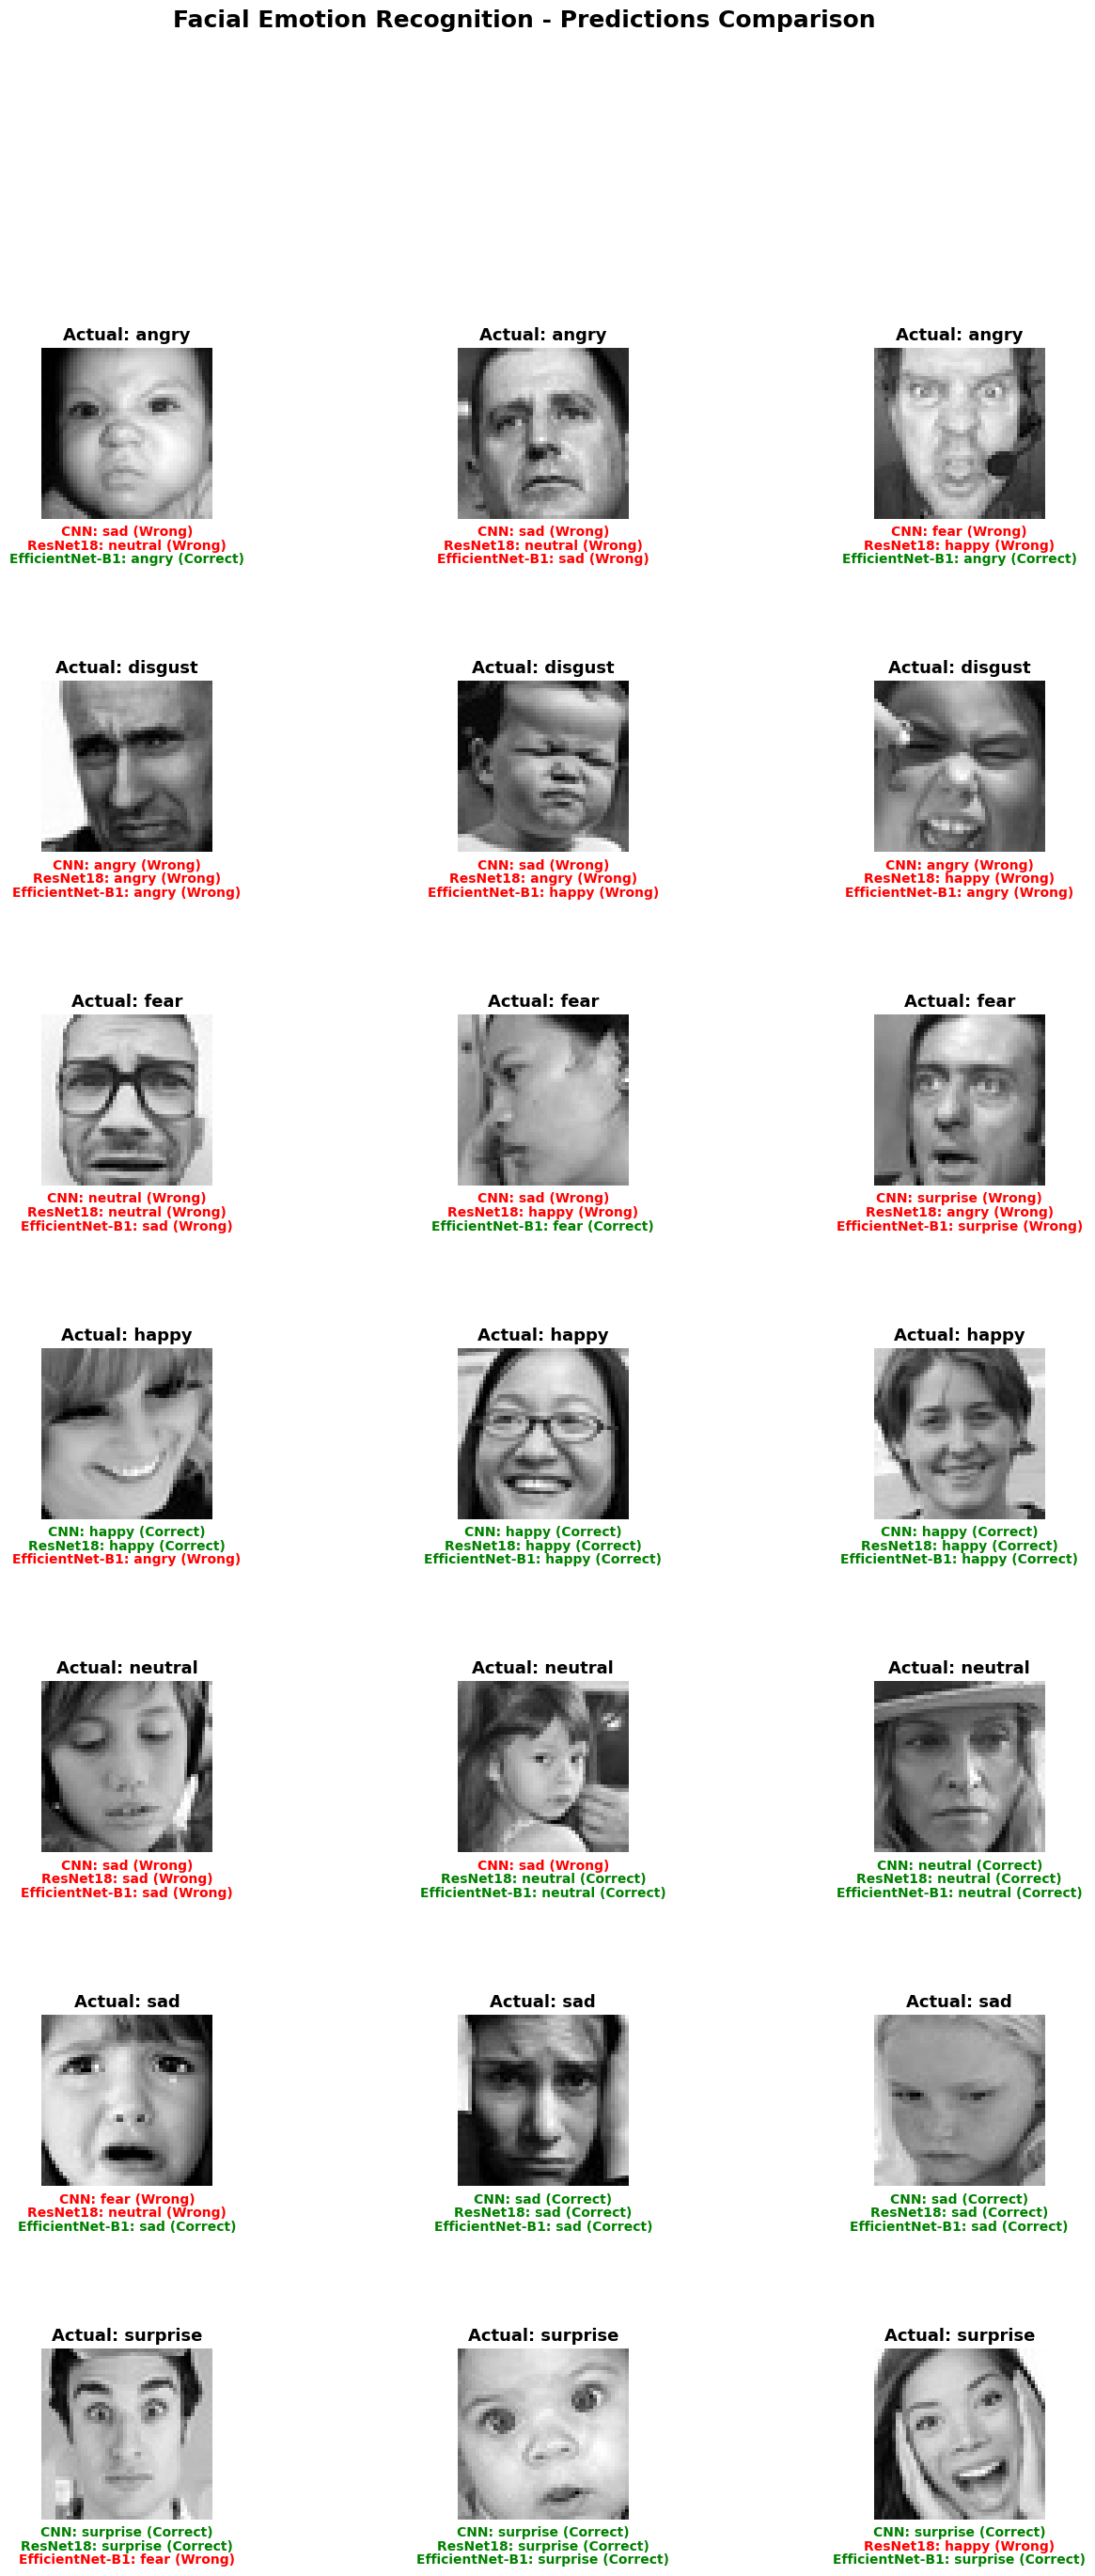

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

# =========================================================
# 1) تجهيز النماذج الثلاثة بوضع التقييم
# =========================================================

cnn_model.eval()
resnet_model.eval()

# البحث تلقائيًا عن نموذج EfficientNet داخل المتغيرات الموجودة
efficientnet_model = None

for name, value in globals().items():
    if isinstance(value, nn.Module):
        if "efficientnet" in type(value).__name__.lower():
            efficientnet_model = value
            print(f"تم العثور على نموذج EfficientNet في المتغير: {name}")
            break

# إذا لم يتم العثور عليه تلقائيًا، أوقفي التنفيذ مع رسالة واضحة
if efficientnet_model is None:
    raise NameError(
        "لم يتم العثور على نموذج EfficientNet-B1 تلقائيًا.\n"
        "إذا كان اسم النموذج مختلفًا، اربطيه يدويًا مثل:\n"
        "efficientnet_model = اسم_متغير_النموذج"
    )

efficientnet_model.eval()

# =========================================================
# 2) أسماء الفئات الحقيقية
# =========================================================

class_names = cnn_test_loader.dataset.classes

# =========================================================
# 3) اختيار 3 صور من كل فئة = 21 صورة
# =========================================================

# استخراج التصنيفات الحقيقية من مجموعة اختبار CNN
test_targets = np.array(cnn_test_loader.dataset.targets)

# تثبيت العشوائية حتى تظهر نفس الصور كل مرة
rng = np.random.default_rng(42)

selected_indices = []

for class_id in range(len(class_names)):
    # جميع الصور التابعة للفئة الحالية
    class_indices = np.where(test_targets == class_id)[0]

    # اختيار 3 صور عشوائية من الفئة
    chosen = rng.choice(class_indices, size=3, replace=False)

    selected_indices.extend(chosen.tolist())

# =========================================================
# 4) دالة مساعدة للحصول على التوقع من أي نموذج
# =========================================================

def get_prediction(model, image_tensor):
    # إضافة بُعد الدفعة batch dimension
    image_tensor = image_tensor.unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image_tensor)
        prediction = outputs.argmax(dim=1).item()

    return prediction

# =========================================================
# 5) عرض 21 صورة مع توقعات النماذج الثلاثة
# =========================================================

fig, axes = plt.subplots(7, 3, figsize=(16, 30))

for i, idx in enumerate(selected_indices):

    # تحديد مكان الصورة داخل الشبكة
    row = i // 3
    col = i % 3
    ax = axes[row, col]

    # -----------------------------------------------------
    # تحميل نفس الصورة من كل DataLoader
    # -----------------------------------------------------

    # صورة CNN (رمادية 48x48 غالبًا)
    cnn_image, true_label = cnn_test_loader.dataset[idx]

    # صورة ResNet18
    resnet_image, _ = resnet_test_loader.dataset[idx]

    # صورة EfficientNet-B1
    eff_image, _ = eff_test_loader.dataset[idx]

    # -----------------------------------------------------
    # الحصول على التوقعات
    # -----------------------------------------------------

    cnn_pred = get_prediction(cnn_model, cnn_image)
    resnet_pred = get_prediction(resnet_model, resnet_image)
    eff_pred = get_prediction(efficientnet_model, eff_image)

    # -----------------------------------------------------
    # تجهيز الصورة للعرض
    # سنعرض نسخة CNN لأنها رمادية وواضحة للمقارنة
    # -----------------------------------------------------

    display_image = cnn_image.squeeze().cpu().numpy()

    # إلغاء التطبيع Normalize
    display_image = (display_image * 0.5) + 0.5
    display_image = np.clip(display_image, 0, 1)

    ax.imshow(display_image, cmap="gray")
    ax.axis("off")

    # -----------------------------------------------------
    # كتابة التصنيف الحقيقي
    # -----------------------------------------------------

    ax.set_title(
        f"Actual: {class_names[true_label]}",
        fontsize=13,
        fontweight="bold"
    )

    # -----------------------------------------------------
    # كتابة توقعات النماذج الثلاثة أسفل الصورة
    # -----------------------------------------------------

    models_predictions = [
        ("CNN", cnn_pred),
        ("ResNet18", resnet_pred),
        ("EfficientNet-B1", eff_pred)
    ]

    for line_num, (model_name, pred) in enumerate(models_predictions):

        # تحديد اللون حسب صحة التوقع
        is_correct = pred == true_label
        color = "green" if is_correct else "red"
        status = "Correct" if is_correct else "Wrong"

        ax.text(
            0.5,                       # منتصف الصورة أفقيًا
            -0.10 - (line_num * 0.08),# مكان السطر أسفل الصورة
            f"{model_name}: {class_names[pred]} ({status})",
            transform=ax.transAxes,
            ha="center",
            fontsize=10,
            color=color,
            fontweight="bold"
        )

# =========================================================
# 6) تنسيق الشكل النهائي
# =========================================================

plt.suptitle(
    "Facial Emotion Recognition - Predictions Comparison",
    fontsize=18,
    fontweight="bold",
    y=1.00
)

plt.subplots_adjust(hspace=0.95, wspace=0.25)
plt.show()

In [ ]:
# استيراد المكتبة
import torch

# البحث عن النماذج الموجودة في الذاكرة
for name, obj in list(globals().items()):
    if isinstance(obj, torch.nn.Module):
        print("Model found:", name)

Model found: model


In [ ]:
# البحث عن ملفات النماذج المحفوظة
import os

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.endswith((".pth", ".pt", ".onnx", ".safetensors")):
            print(os.path.join(root, file))

In [ ]:
# استيراد المكتبة
import torch

# معرفة نوع النموذج الموجود في الذاكرة
print("Model type:", type(model).__name__)

# عرض اسم بنية النموذج
print("Model architecture:", model.__class__.__module__)

# معرفة عدد فئات الإخراج
with torch.no_grad():
    print("Classifier:", model.get_classifier() if hasattr(model, "get_classifier") else "Check model architecture")

Model type: EfficientNet
Model architecture: timm.models.efficientnet
Classifier: Linear(in_features=1280, out_features=7, bias=True)


In [ ]:
# استيراد المكتبات
import torch
import timm

# عرض إعدادات النموذج
print("Model configuration:")
print(model.default_cfg.get("architecture", "Unknown"))

# عرض عدد فئات المشاعر
print("Number of classes:", model.get_classifier().out_features)

# التأكد من وضع التقييم
model.eval()

# حفظ أوزان النموذج الموجود في الذاكرة
torch.save(
    model.state_dict(),
    "efficientnet_b1_fer2013.pth"
)

print("Model saved successfully!")

Model configuration:
efficientnet_b1
Number of classes: 7
Model saved successfully!


In [ ]:
# استيراد المكتبات
import torch
import time

# تحويل النموذج إلى وضع التقييم
model.eval()

# تحديد الجهاز الذي يعمل عليه النموذج
device = next(model.parameters()).device

# التأكد من جاهزية النموذج
print("Model:", model.default_cfg.get("architecture"))
print("Device:", device)
print("Model ready for evaluation!")

Model: efficientnet_b1
Device: cpu
Model ready for evaluation!


In [ ]:
# تثبيت المكتبات المطلوبة
%pip install -q onnx onnxruntime onnxscript

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 61.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 754.2/754.2 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 185.8/185.8 kB 14.4 MB/s eta 0:00:00


In [ ]:
# استيراد المكتبات
import torch
import os

# تجهيز النموذج للتصدير
model.eval()

# نقل النموذج مؤقتًا إلى المعالج
model_cpu = model.to("cpu")

# إعداد صورة تجريبية بحجم EfficientNet-B1 المستخدم في مشروعك
dummy_input = torch.randn(1, 3, 240, 240)

# تحديد اسم ملف ONNX
onnx_path = "efficientnet_b1_fer2013.onnx"

# تصدير النموذج إلى ONNX
torch.onnx.export(
    model_cpu,
    (dummy_input,),
    onnx_path,
    input_names=["input"],
    output_names=["output"],
    opset_version=18,
    dynamo=True
)

# التأكد من إنشاء الملف
print("ONNX export successful!")
print("File exists:", os.path.exists(onnx_path))

[torch.onnx] Obtain model graph for `EfficientNet([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `EfficientNet([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...


/usr/lib/python3.13/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)


[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
ONNX export successful!
File exists: True


In [ ]:
# استيراد مكتبات ONNX
import onnx
import onnxruntime as ort

# تحديد مسار النموذج
onnx_path = "efficientnet_b1_fer2013.onnx"

# التحقق من سلامة بنية النموذج
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)

# إنشاء جلسة تشغيل باستخدام المعالج CPU
session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

# عرض معلومات المدخلات والمخرجات
print("ONNX validation successful!")
print("Input:", session.get_inputs()[0].shape)
print("Output:", session.get_outputs()[0].shape)
print("Model ready for deployment!")

ONNX validation successful!
Input: [1, 3, 240, 240]
Output: [1, 7]
Model ready for deployment!


In [ ]:
# استيراد المكتبات
import torch
import numpy as np
import time

# إعداد النموذج للعمل على CPU للمقارنة العادلة
model_cpu = model.to("cpu").eval()

# إنشاء مدخل تجريبي مطابق لحجم النموذج
sample = torch.randn(1, 3, 240, 240)
sample_np = sample.numpy()

# الحصول على أسماء مدخلات ومخرجات ONNX
input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

# تسخين النموذجين لتقليل تأثير التشغيل الأول
with torch.inference_mode():
    for _ in range(10):
        _ = model_cpu(sample)

for _ in range(10):
    _ = session.run([output_name], {input_name: sample_np})

# قياس سرعة PyTorch على CPU
runs = 30

with torch.inference_mode():
    start = time.perf_counter()
    for _ in range(runs):
        pytorch_output = model_cpu(sample)
    pytorch_time = (time.perf_counter() - start) / runs * 1000

# قياس سرعة ONNX Runtime على CPU
start = time.perf_counter()

for _ in range(runs):
    onnx_output = session.run(
        [output_name],
        {input_name: sample_np}
    )[0]

onnx_time = (time.perf_counter() - start) / runs * 1000

# مقارنة المخرجات للتحقق من تقارب النتائج
max_diff = np.max(
    np.abs(pytorch_output.numpy() - onnx_output)
)

# عرض النتائج
print("PyTorch CPU latency:", round(pytorch_time, 2), "ms")
print("ONNX CPU latency:", round(onnx_time, 2), "ms")
print("Maximum output difference:", max_diff)
print("Speedup:", round(pytorch_time / onnx_time, 2), "x")

PyTorch CPU latency: 161.75 ms
ONNX CPU latency: 45.76 ms
Maximum output difference: 1.1641532e-10
Speedup: 3.53 x


In [ ]:
# البحث عن إعدادات معالجة الصور المستخدمة في المشروع
for name in [
    "test_transform",
    "val_transform",
    "transform_eff",
    "test_transform_eff",
    "data_config"
]:
    if name in globals():
        print(f"\n{name}:")
        print(globals()[name])

In [ ]:
# استيراد مكتبة معالجة الصور
from torchvision import transforms

# البحث عن متغيرات معالجة الصور في الذاكرة
for name, obj in list(globals().items()):

    # البحث عن أسماء مرتبطة بمعالجة الصور
    if any(word in name.lower() for word in
           ["transform", "dataset", "loader"]):

        # استبعاد المتغيرات الداخلية
        if not name.startswith("_"):
            print(name, ":", type(obj).__name__)

            # عرض إعدادات تحويل الصور إذا كانت متوفرة
            if hasattr(obj, "transform"):
                print("Transform:", obj.transform)

transforms : module


In [ ]:
# استيراد المكتبات
import torch
import timm

# عرض إعدادات الصور الافتراضية لنموذج EfficientNet-B1
print("EfficientNet-B1 Configuration:")

print(
    "Input size:",
    model.default_cfg.get("input_size")
)

print(
    "Mean:",
    model.default_cfg.get("mean")
)

print(
    "Std:",
    model.default_cfg.get("std")
)

print(
    "Interpolation:",
    model.default_cfg.get("interpolation")
)

EfficientNet-B1 Configuration:
Input size: (3, 240, 240)
Mean: (0.5, 0.5, 0.5)
Std: (0.5, 0.5, 0.5)
Interpolation: bicubic


In [ ]:
# استيراد المكتبة اللازمة
import torch

# البحث عن إعدادات معالجة الصور في خلايا المشروع المحفوظة
from IPython import get_ipython

# البحث عن كود معالجة الصور في سجل تنفيذ الخلايا
history = get_ipython().history_manager.input_hist_raw

for i, code in enumerate(history):
    if "efficientnet_b1" in code.lower() or "240, 240" in code:
        if any(word in code.lower() for word in ["transform", "normalize", "resize"]):
            print(f"\n--- Cell {i} ---")
            print(code[:2500])


--- Cell 24 ---
# استيراد المكتبة اللازمة
import torch

# البحث عن إعدادات معالجة الصور في خلايا المشروع المحفوظة
from IPython import get_ipython

# البحث عن كود معالجة الصور في سجل تنفيذ الخلايا
history = get_ipython().history_manager.input_hist_raw

for i, code in enumerate(history):
    if "efficientnet_b1" in code.lower() or "240, 240" in code:
        if any(word in code.lower() for word in ["transform", "normalize", "resize"]):
            print(f"\n--- Cell {i} ---")
            print(code[:2500])


In [ ]:
%pip install -q gradio

In [ ]:
# استيراد المكتبات المطلوبة
import gradio as gr
import onnxruntime as ort
import numpy as np
import torch
from torchvision import transforms
from torchvision.transforms import InterpolationMode

# أسماء فئات المشاعر بنفس ترتيب FER2013
class_names = [
    "angry",
    "disgust",
    "fear",
    "happy",
    "neutral",
    "sad",
    "surprise"
]

# تحميل نموذج ONNX المحفوظ
session = ort.InferenceSession(
    "efficientnet_b1_fer2013.onnx",
    providers=["CPUExecutionProvider"]
)

# إعداد معالجة الصور المطابقة لكود الاختبار
preprocess = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize(
        (240, 240),
        interpolation=InterpolationMode.BILINEAR
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# دالة التنبؤ بالمشاعر من الصورة
def predict_emotion(image):

    # التحقق من رفع صورة
    if image is None:
        return {}

    # معالجة الصورة وإضافة بُعد الدفعة
    tensor = preprocess(image).unsqueeze(0)
    input_data = tensor.numpy().astype(np.float32)

    # تشغيل نموذج ONNX
    input_name = session.get_inputs()[0].name
    output = session.run(None, {input_name: input_data})[0]

    # تحويل المخرجات إلى احتمالات باستخدام Softmax
    logits = output[0]
    logits = logits - np.max(logits)
    exp_values = np.exp(logits)
    probabilities = exp_values / np.sum(exp_values)

    # تجهيز نتائج المشاعر السبع
    return {
        name: float(probability)
        for name, probability in zip(class_names, probabilities)
    }

# إنشاء واجهة Gradio
demo = gr.Interface(
    fn=predict_emotion,
    inputs=gr.Image(type="pil", label="Upload Facial Image"),
    outputs=gr.Label(
        num_top_classes=7,
        label="Emotion Prediction"
    ),
    title="Facial Emotion Recognition",
    description=(
        "EfficientNet-B1 | ONNX Runtime | FER2013\n"
        "Upload a facial image to predict one of seven emotion categories."
    )
)

# تشغيل التطبيق
demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://72301034b34771116f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# استيراد المكتبات
import numpy as np
from PIL import Image
from IPython.display import display

# إنشاء صورة اختبار تجريبية
test_image = Image.new("RGB", (240, 240), color="gray")

# اختبار دالة التنبؤ
results = predict_emotion(test_image)

# التحقق من نتائج النموذج
print("Prediction test completed!")

for emotion, probability in sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{emotion}: {probability * 100:.2f}%")

# التأكد من أن مجموع الاحتمالات يساوي تقريبًا 100%
print("Total probability:", sum(results.values()))

Prediction test completed!
sad: 14.29%
angry: 14.29%
fear: 14.29%
neutral: 14.29%
disgust: 14.29%
surprise: 14.29%
happy: 14.28%
Total probability: 0.9999999701976776


In [ ]:
# استيراد المكتبات
import numpy as np
from PIL import Image
from IPython.display import display

# إنشاء صورة اختبار تجريبية
test_image = Image.new("RGB", (240, 240), color="gray")

# اختبار دالة التنبؤ
results = predict_emotion(test_image)

# التحقق من نتائج النموذج
print("Prediction test completed!")

for emotion, probability in sorted(
    results.items(),
    key=lambda item: item[1],
    reverse=True
):
    print(f"{emotion}: {probability * 100:.2f}%")

# التأكد من أن مجموع الاحتمالات يساوي تقريبًا 100%
print("Total probability:", sum(results.values()))

Prediction test completed!
sad: 14.29%
angry: 14.29%
fear: 14.29%
neutral: 14.29%
disgust: 14.29%
surprise: 14.29%
happy: 14.28%
Total probability: 0.9999999701976776


In [ ]:
# استيراد مكتبة حفظ النتائج
import pandas as pd

# إنشاء جدول مقارنة الأداء
results_df = pd.DataFrame({
    "Runtime": ["PyTorch CPU", "ONNX Runtime CPU"],
    "Latency (ms)": [161.75, 45.76]
})

# حفظ الجدول بصيغة CSV
results_df.to_csv("optimization_results.csv", index=False)

# عرض النتائج
display(results_df)

print("Optimization results saved successfully!")

,Runtime,Latency (ms)
0,PyTorch CPU,161.75
1,ONNX Runtime CPU,45.76


Optimization results saved successfully!


In [ ]:
# استيراد المكتبة
import pandas as pd

# إنشاء جدول نتائج تحسين الأداء
optimization_df = pd.DataFrame({
    "Runtime": ["PyTorch CPU", "ONNX Runtime CPU"],
    "Latency (ms)": [161.75, 45.76]
})

# حفظ النتائج
optimization_df.to_csv(
    "optimization_results.csv",
    index=False
)

# عرض النتائج
display(optimization_df)

print("Optimization results saved!")

,Runtime,Latency (ms)
0,PyTorch CPU,161.75
1,ONNX Runtime CPU,45.76


Optimization results saved!
